Matched+parsed: 18 | skipped (no AM/cat): 34 | failed parse: 0


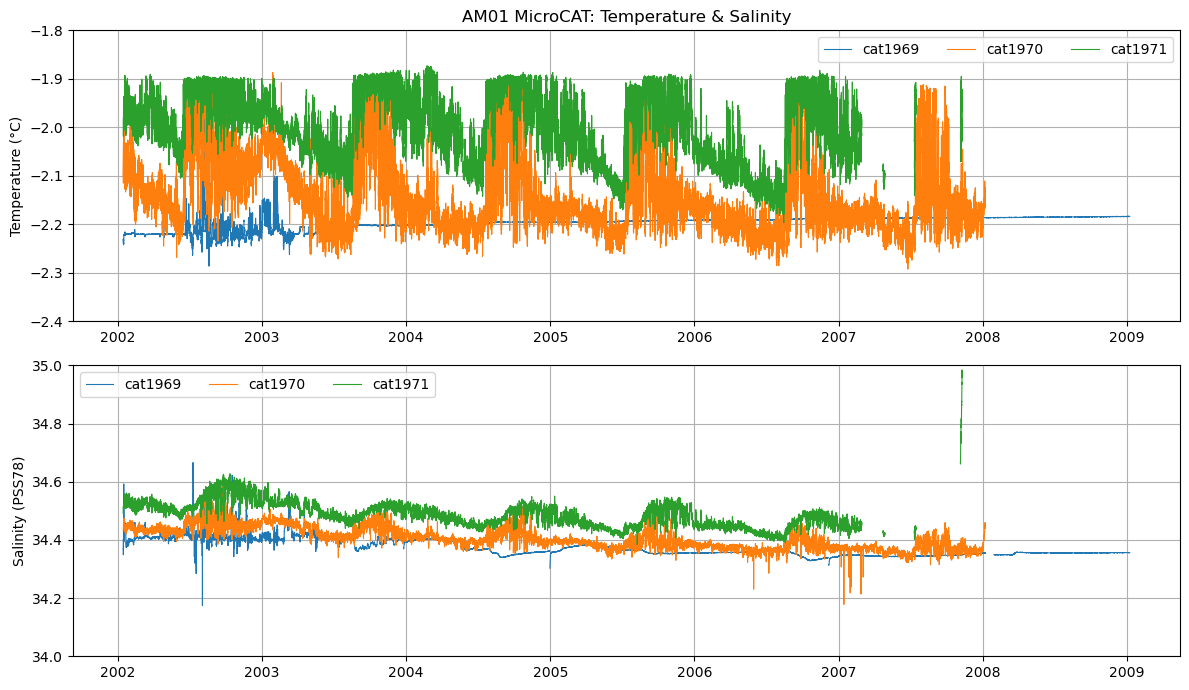

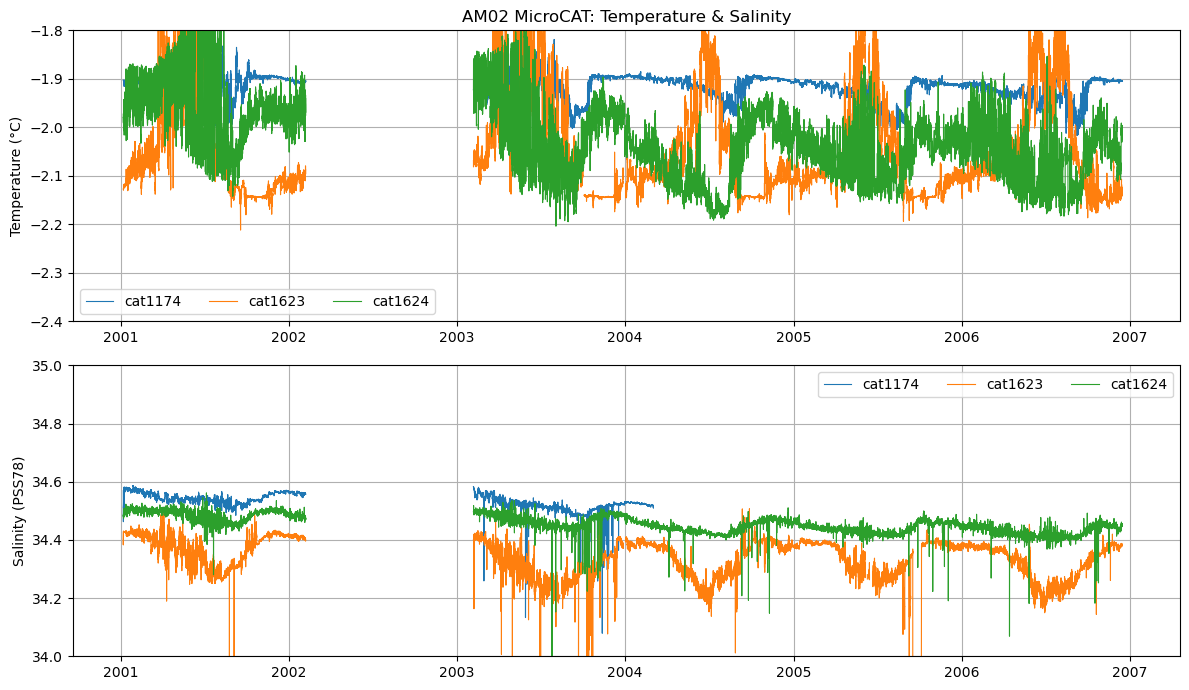

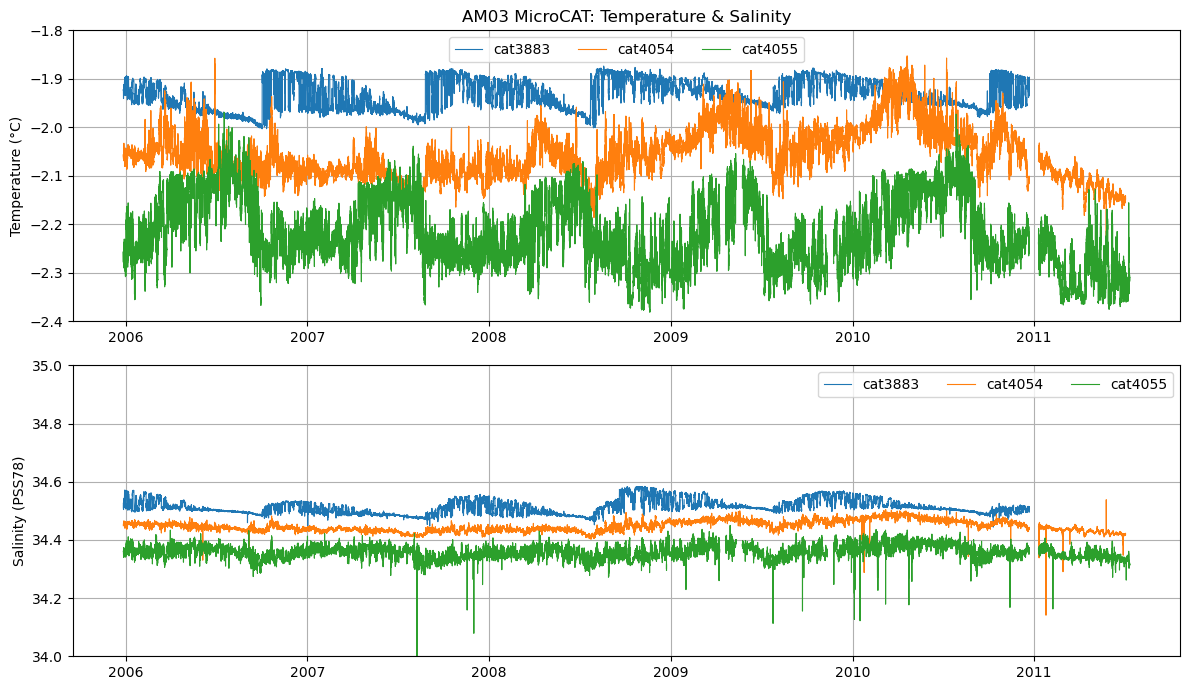

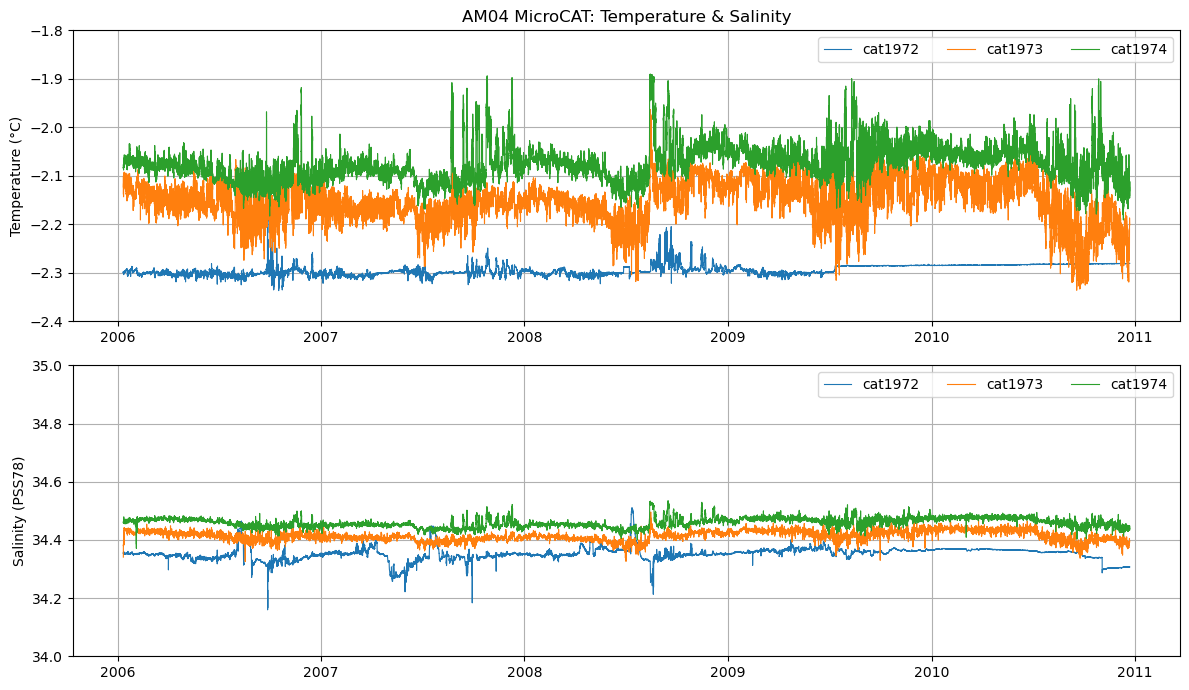

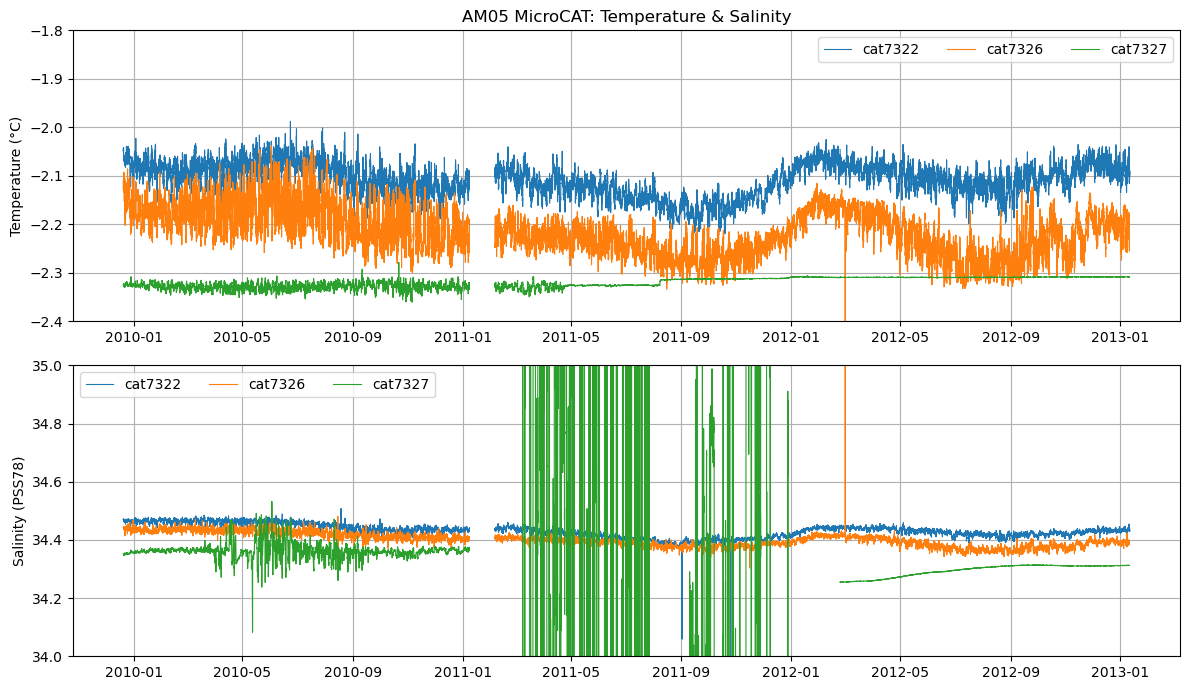

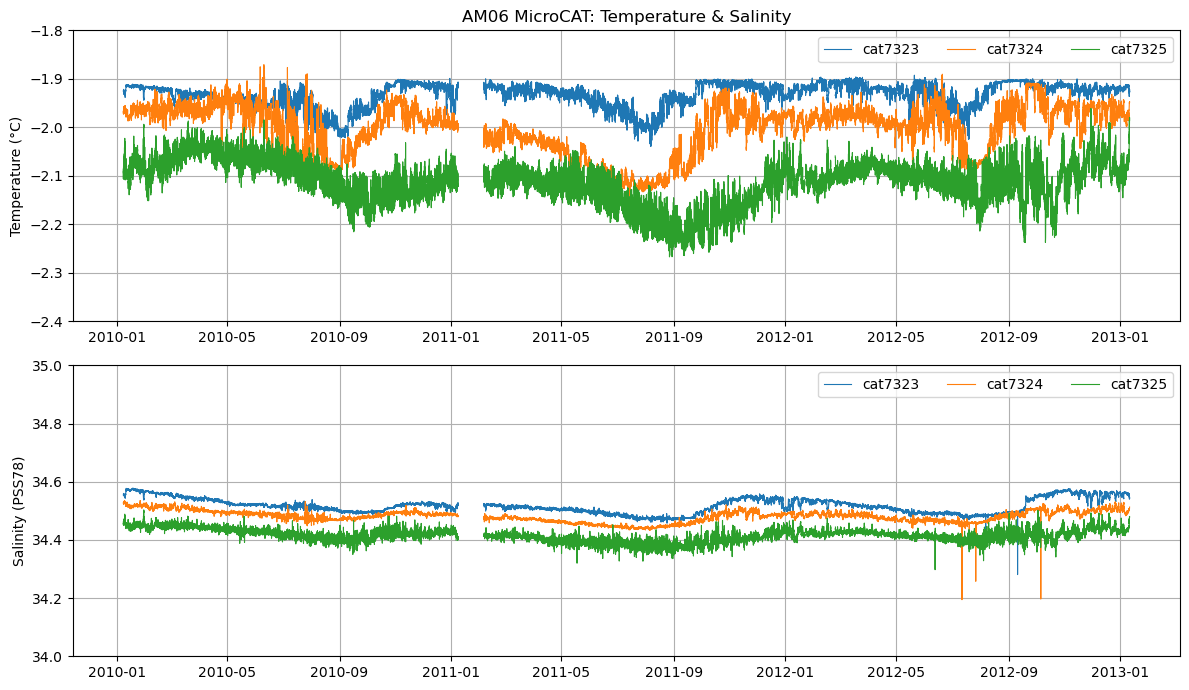

In [92]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
import sys

# Establish the downloaded AMISOR database as the root from which to find MicroCAT data
root = Path("/Users/alex/Library/CloudStorage/OneDrive-UniversityofTasmania/Alex Doherty Honours 2026/Data/AMISOR")

# Find all MicroCAT data files 
dat_files = sorted(root.rglob("*.dat"))

# Regex (regular expression): find AM01..AM06 anywhere in path/name + cat#### filename
rx = re.compile(r"(AM\d{2}).*?\bcat(\d+)(?:_[^/]*)?\.dat\b", re.IGNORECASE)

# Define a function for parsing MicroCAT data to pandas dataframe object
def parse_microcat_dat(path: Path, skiprows: int = 5) -> pd.DataFrame:
    # Load the file containing data
    data = np.loadtxt(path, skiprows=skiprows)

    # There are several columns, but we are interested in parsing in values related to temperature, conductivity, pressure, salinity, and time 
    temp = data[:, 1]
    cond = data[:, 2]
    pres = data[:, 3]
    sal  = data[:, 4]

    day    = data[:, 5].astype(int)
    month  = data[:, 6].astype(int)
    year   = data[:, 7].astype(int)
    hour   = data[:, 8].astype(int)
    minute = data[:, 9].astype(int)
    second = data[:,10].astype(int)

    # Convert parsed datetime data into a standardised pandas datatime object
    time = pd.to_datetime(
        dict(year=year, month=month, day=day, hour=hour, minute=minute, second=second),
        errors="coerce"
    )

    # Store all parsed data into a dataframe object, using the datetime object as the index
    df = pd.DataFrame({"temperature": temp, "conductivity": cond, "pressure": pres, "salinity": sal}, index=time).sort_index()
    df.index.name = "time"

    # Replace all ~-999 values with NaN
    df = df.mask(np.isclose(df, -999.0, atol=1e-6))
    
    # OPTIONAL: Delete lines of data where datetime cannot be parsed properly
    # df = df[~df.index.isna()]
    
    return df

# defaultdict(list) creates a dictionary where any new/missing key is automatically assigned to a new, empty list
# i.e. the below code iterates over all the recognised .dat files, parsing the MicroCAT data to a unique dataframe object, and then adding each dataframe object to a list
# of dataframe objects identified by a key corresponding to the AM and cat number

# It will look something like below:
# dfs_list = {
#     ("AM01","1969"): [df_part1, df_part2],
#     ("AM01","1970"): [df_part1],
#     ("AM02","1174"): [df_part1, df_part2, df_part3],
# }

# Since there can be multiple .dat files for a single cat (some observational data downloads from different years have been added to the database in separate files)
dfs_list = defaultdict(list)          # keyed by (AMxx, cat####)
skipped = []                          # files that don’t match the pattern
failed = []                           # files that match but can’t be parsed

# Iterate over all recognised .dat files
for p in dat_files:
    # Skip files containing certain words
    exclude_words = ["uncorrected", "mean"]
    name_lower = p.name.lower()
    if any(word in name_lower for word in exclude_words):
        continue
    
    # Use regex to identify borehole (AMXX) and cat#### in .dat file
    m = rx.search(str(p))
    if not m:
        skipped.append(p)
        continue

    # Determine the borehole id and cat id from the filename
    am_id = m.group(1).upper()
    cat_id = m.group(2)  # keep as string; cast to int if you prefer

    # Parse the MicroDAT data and assign to a dataframe object
    # Also assign the borehole, cat id, and source filename to the dataframe
    try:
        df = parse_microcat_dat(p, skiprows=5)
        df["AM"] = am_id
        df["cat"] = int(cat_id)
        df["source_file"] = p.name

        # Use the borehole and cat ids as keys to identify the list of dataframe objects
        dfs_list[(am_id, cat_id)].append(df)
    
    except Exception as e:
        failed.append((p, repr(e)))

# OPTIONAL: one combined dataframe
# df_all = pd.concat(dfs.values(), axis=0).sort_index() if dfs else pd.DataFrame()

# Set up a dataframe object in which to concatenate the parsed dataframe objects corresponding to each AM and cat
dfs = {}    # keyed by (AMxx, cat####)

# Set up a function to resolve different cases for where there are duplicates between data files for a specific timestamp
def resolve_duplicates(df):
    resolved_rows = []
    flagged = []

    # Iterate over each group defined by each timestep => matching timesteps have been grouped together
    for timestamp, group in df.groupby(df.index):

        # If there is a unique timestamp, then there is no duplicate and we are done
        if len(group) == 1:
            resolved_rows.append(group.iloc[0])
            continue

        # Within the duplicate timestamps, we want to only select numerical data types (i.e. temp, cond, pres, sal) to compare
        numeric = group.select_dtypes(include=[np.number])

        # Case 1: Data in duplicated timestamps is identical (i.e. there is only one unique set of data values)
        # Arbitrarily take the first row
        if numeric.nunique().max() == 1:
            resolved_rows.append(group.iloc[0])
            continue

        # Case 2: Data in 1+ duplicated timestamps is all -999
        # Identify rows where all numeric columns are -999
        mask_all_bad = numeric.isna().all(axis=1)

        # If at least one good row exists
        if (~mask_all_bad).any():
        
            # Drop all fully-bad rows
            group_clean = group[~mask_all_bad]
            numeric_clean = numeric[~mask_all_bad]
        
            # Case 1: There is remaining duplicated timesteps with identical data
            if numeric_clean.nunique().max() == 1:
                resolved_rows.append(group_clean.iloc[0])
                continue
        
            # Case 3: There is remaining duplicated timesteps with conflicting data
            print("\nConflict at:", timestamp)
            print(group_clean)
            flagged.append((timestamp, group_clean))
        
            resolved_rows.append(group_clean.iloc[0])
            continue

        # Case 3: Different valid values → flag for inspection
        print("\nConflict at:", timestamp)
        print(group)
        flagged.append((timestamp, group))

        # For now, keep first arbitrarily
        resolved_rows.append(group.iloc[0])

    result = pd.DataFrame(resolved_rows)
    result.index.name = "time"

    return result.sort_index(), flagged
    
# Iterate over list of dataframes (pertaining to individual .dat files) defined by each key in the dictionary, combining each list of dataframes into one dataframe
for key, parts in dfs_list.items():
    # Stack all dataframes in the list corresponding to a key and sort by time => then concatenate into one dataframe
    out = pd.concat(parts).sort_index()

    # Since there is minor overlap in data timestamps between files, we choose to keep the last occurrence here
    out, flagged_conflicts = resolve_duplicates(out)

    dfs[key] = out

print(f"Matched+parsed: {len(dfs)} | skipped (no AM/cat): {len(skipped)} | failed parse: {len(failed)}")

def plot_borehole(dfs, am_id, ylim_temp=None, ylim_sal=None, resample=None):
    # Sort through dataframe keys and extract the keys containing the specified borehole is (AMXX)
    keys = sorted([(a, c) for (a, c) in dfs.keys() if a == am_id], key=lambda x: int(x[1]))
    
    if not keys:
        print(f"No data for {am_id}")
        return

    fig, (axT, axS) = plt.subplots(2, 1, figsize=(12, 7), sharex=False)

    for (_, cat_id) in keys:
        dfp = dfs[(am_id, cat_id)]

        # Optional: smooth/downsample to make multi-year plots readable
        # if resample is not None:
        #     dfp = df.resample(resample).mean(numeric_only=True)
        # else:
        #     dfp = df

        axT.plot(dfp.index, dfp["temperature"], lw=0.8, label=f"cat{cat_id}")
        axS.plot(dfp.index, dfp["salinity"],    lw=0.8, label=f"cat{cat_id}")

    axT.set_ylabel("Temperature (°C)")
    axS.set_ylabel("Salinity (PSS78)")
    #axS.set_xlabel("Year")
    axT.set_title(f"{am_id} MicroCAT: Temperature & Salinity")

    axT.legend(ncols=3)
    axS.legend(ncols=3)

    if ylim_temp is not None: axT.set_ylim(*ylim_temp)
    if ylim_sal  is not None: axS.set_ylim(*ylim_sal)

    axT.grid(True); axS.grid(True)
    plt.tight_layout()
    plt.show()

# --- make one figure per borehole ---
boreholes = sorted({am for (am, _) in dfs.keys()})
for am_id in boreholes:
    plot_borehole(dfs, am_id, (-2.4, -1.8), (34, 35), resample="None")  # change "D" to None / "H" / "7D" etc.